# 07 · Le réseau de similarité des Pokémon

L'idée : on décrit chaque Pokémon par un **vecteur** (ses types, ses stats, son gabarit, sa forme, ses couleurs), on relie chaque Pokémon à ceux qui lui ressemblent le plus (**graphe des k plus proches voisins**, comme au TP4), puis on analyse ce graphe avec les outils du TP3 : communautés (Louvain), centralités, comparaison avec un graphe aléatoire.

La question derrière : **est-ce que la place d'un Pokémon dans ce réseau dit quelque chose de sa popularité ?** Par exemple, un Pokémon « unique » (peu de voisins proches) est-il plus aimé qu'un Pokémon qui ressemble à plein d'autres ? Les Pokémon populaires se ressemblent-ils entre eux ?

Enfin on fait un **node2vec** (marches aléatoires + Word2Vec, comme au TP4) et un **t-SNE** pour avoir une carte 2D du réseau.

Pour la popularité, on reste sur ce qu'on a fait dans les notebooks 01 et 02 : pas de score combiné, chaque source est regardée à part, en percentile.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from networkx.algorithms.community import louvain_communities, modularity
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE, trustworthiness

pd.set_option("display.max_columns", 50)
SEED = 0   # graine fixe pour que les résultats soient reproductibles
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
couleurs = pd.read_csv(OUT / "couleurs_sprites.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
sur = pd.read_csv(OUT / "sur_sous_cotes.csv", index_col="dex")
print(table.shape, couleurs.shape, pop.shape, sur.shape)

(1025, 31) (1025, 13) (1025, 18) (1025, 11)


## 1. Le vecteur de chaque Pokémon

On décrit chaque Pokémon par **6 blocs** de variables, qui parlent uniquement de son apparence et de son rôle en jeu :
- **types** : une colonne par type (18), qui vaut 1 si le Pokémon a ce type, en premier ou en second ;
- **stats** : les 6 statistiques de combat ;
- **gabarit** : taille et poids, en log (le poids va de 0,1 kg à 999,9 kg, sans le log quelques géants écraseraient tout) ;
- **couleur officielle** (PokéAPI) en indicatrices ;
- **forme du corps** (PokéAPI) en indicatrices ;
- **couleurs de l'image** (notebook 03, sans le contour noir) : nombre de couleurs, saturation et luminosité, teinte dominante.

On a hésité pour la couleur officielle et la forme du corps, parce que ce sont des étiquettes un peu grossières. On décide quand même de **les garder** : ce sont des attributs de design, exactement ce qu'on veut comparer, et la forme du corps est la seule info qu'on a sur la silhouette du Pokémon. On verra plus bas qu'elles pèsent beaucoup dans les communautés.

On ne met **pas** la génération, le stade, starter ou légendaire, ni la popularité : on veut un réseau de ressemblance « physique », pour ensuite regarder comment la popularité s'y répartit. Si on mettait la popularité dedans, on retrouverait forcément des voisins populaires, et ça ne voudrait rien dire.

In [2]:
# types : un Pokémon peut en avoir deux
types = pd.get_dummies(table["type1"]).astype(int).add(pd.get_dummies(table["type2"]).astype(int).reindex(columns=pd.get_dummies(table["type1"]).columns, fill_value=0), fill_value=0)
print("types :", types.shape, "| valeurs :", np.unique(types.values))
stats = table[["pv", "attaque", "defense", "attaque_spe", "defense_spe", "vitesse"]]
gabarit = np.log(table[["taille_m", "poids_kg"]]).add_prefix("log_")
couleur_off = pd.get_dummies(table["couleur"], prefix="coul").astype(int)
forme = pd.get_dummies(table["forme_corps"], prefix="forme").astype(int)
# la teinte est un angle (0° = 360° = rouge) : on la passe en cosinus et sinus pour que 359° soit proche de 1°
t = np.deg2rad(couleurs["dom_teinte"])
sprite = pd.DataFrame({"nb_couleurs": couleurs["nb_couleurs"], "sat_moy": couleurs["saturation_moyenne"],
                       "lum_moy": couleurs["luminosite_moyenne"], "dom_sat": couleurs["dom_saturation"],
                       "teinte_cos": np.cos(t), "teinte_sin": np.sin(t)})
blocs = {"types": types, "stats": stats, "gabarit": gabarit, "couleur_off": couleur_off, "forme": forme, "sprite": sprite}
for nom, b in blocs.items():
    print(f"{nom:12s} {b.shape[1]:3d} colonnes | manquants : {b.isna().sum().sum()}")

types : (1025, 18) | valeurs : [0 1]
types         18 colonnes | manquants : 0
stats          6 colonnes | manquants : 0
gabarit        2 colonnes | manquants : 0
couleur_off   10 colonnes | manquants : 0
forme         14 colonnes | manquants : 0
sprite         6 colonnes | manquants : 0


On a 56 colonnes en tout, réparties en 6 blocs, et aucun manquant. Les types valent bien 0 ou 1 (un Pokémon n'a jamais deux fois le même type).

**Pondération.** Si on colle les blocs tels quels, le bloc qui a le plus de colonnes (les 18 types) pèse beaucoup plus que le gabarit (2 colonnes). On n'a pas de raison de dire que le type compte plus que la taille pour juger si deux Pokémon se ressemblent, donc on décide de donner **le même poids à chaque bloc** :
1. on **standardise** chaque colonne (moyenne 0, écart-type 1), comme au TP2 ;
2. on divise chaque bloc par la racine de son nombre de colonnes, pour que chaque bloc ait le même poids total dans la distance.

In [3]:
parties = []
for nom, b in blocs.items():
    z = StandardScaler().fit_transform(b.astype(float))
    parties.append(pd.DataFrame(z / np.sqrt(b.shape[1]), index=b.index, columns=[f"{nom}:{c}" for c in b.columns]))
X = pd.concat(parties, axis=1).loc[table.index]
print(X.shape)
# vérification : la variance totale de chaque bloc
X.var(ddof=0).groupby(X.columns.str.split(":").str[0]).sum().round(2)

(1025, 56)


couleur_off    1.0
forme          1.0
gabarit        1.0
sprite         1.0
stats          1.0
types          1.0
dtype: float64

Après la pondération, chaque bloc a bien une variance totale de 1 : aucun bloc ne domine juste parce qu'il a plus de colonnes.

## 2. Le graphe des k plus proches voisins

On mesure la ressemblance avec la **similarité cosinus** (comme au TP4). Chaque Pokémon est relié à ses k plus proches voisins ; si A est dans les voisins de B ou B dans ceux de A, on met une arête (le graphe est non orienté), avec un poids égal à la similarité.

D'abord, l'effet de k sur le graphe :

In [4]:
nn = NearestNeighbors(metric="cosine").fit(X.values)
dist, idx = nn.kneighbors(X.values, n_neighbors=31)
noeuds = X.index.to_numpy()

def graphe_knn(k):
    G = nx.Graph()
    G.add_nodes_from(noeuds)
    for i in range(len(noeuds)):
        for j, d in zip(idx[i, 1:k + 1], dist[i, 1:k + 1]):
            G.add_edge(noeuds[i], noeuds[j], weight=1 - d)
    return G

lignes = []
for k in [2, 3, 5, 8, 10, 15, 20, 30]:
    g = graphe_knn(k)
    cc = list(nx.connected_components(g))
    lignes.append({"k": k, "aretes": g.number_of_edges(), "composantes": len(cc),
                   "taille plus grande": max(map(len, cc)), "degre moyen": 2 * g.number_of_edges() / g.number_of_nodes()})
pd.DataFrame(lignes).set_index("k").round(1)

,aretes,composantes,taille plus grande,degre moyen
k,,,,
2,1493,4,1016,2.9
3,2210,1,1025,4.3
5,3614,1,1025,7.1
8,5674,1,1025,11.1
10,7022,1,1025,13.7
15,10334,1,1025,20.2
20,13516,1,1025,26.4
30,20010,1,1025,39.0


Avec k = 2, le graphe est coupé en 4 morceaux. Dès k = 3, tous les Pokémon sont dans une seule composante. Plus k augmente, plus il y a d'arêtes.

On choisit **k = 10**. Avec moins (3 à 5), le graphe est connexe mais très « maigre » : un Pokémon n'a que quelques voisins, et une seule ressemblance un peu bizarre change beaucoup sa place. Avec beaucoup plus (20, 30), on relie des Pokémon qui ne se ressemblent plus vraiment et les groupes se mélangent. 10, c'est le même ordre de grandeur que ce qu'on a utilisé au TP4. Avec k = 10, chaque Pokémon a en moyenne 13,7 voisins (plus que 10, parce qu'on garde aussi l'arête quand A a choisi B mais pas l'inverse).

In [5]:
K = 10
G = graphe_knn(K)
for n in G:
    G.nodes[n]["nom"] = table.loc[n, "nom_fr"]
print(G)
degres = pd.Series(dict(G.degree()))
degres.describe()

Graph with 1025 nodes and 7022 edges


count    1025.000000
mean       13.701463
std         4.007396
min        10.000000
25%        11.000000
50%        13.000000
75%        15.000000
max        31.000000
dtype: float64

Le graphe final a 1 025 nœuds et 7 022 arêtes. Le degré va de 10 (le minimum, ses 10 propres voisins) à 31.

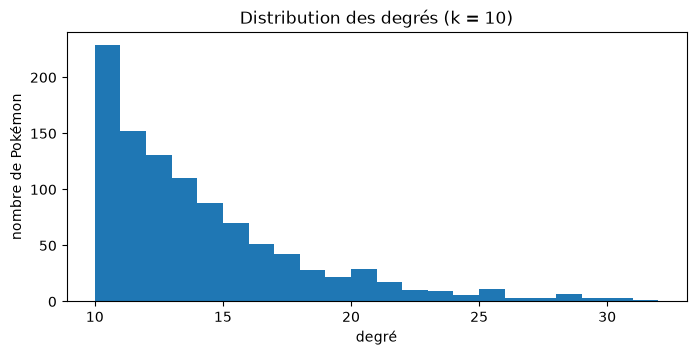

Pokémon les plus « connectés » :


Carapuce    31
Miraidon    30
Ama-Ama     30
Melmetal    30
Maganon     29
Korillon    29
Groudon     29
Crèmy       28
Pimito      28
Akwakwak    28
dtype: int64

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(degres, bins=range(degres.min(), degres.max() + 2))
ax.set_xlabel("degré"); ax.set_ylabel("nombre de Pokémon")
ax.set_title(f"Distribution des degrés (k = {K})")
plt.show()
print("Pokémon les plus « connectés » :")
degres.sort_values(ascending=False).head(10).rename(table["nom_fr"])

Les Pokémon avec le plus de voisins (Carapuce, Miraidon, Ama-Ama, Melmetal…) ressemblent à beaucoup d'autres : ils sont choisis comme voisins par plein de Pokémon.

In [7]:
# les voisins de quelques Pokémon connus : est-ce que le graphe a du sens ?
for d in [6, 25, 94, 133, 448]:
    v = sorted(G[d], key=lambda n: -G[d][n]["weight"])[:6]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[v, "nom_fr"]))

Dracaufeu    → Maganon, Magmar, Goupelin, Aflamanoir, Braségali, Ho-Oh
Pikachu      → Pohm, Pichu, Posipi, Voltoutou, Négapi, Pohmotte
Ectoplasma   → Salarsen, Nidoking, Mewtwo, Wimessir, Magirêve, Mandrillon
Évoli        → Ponchiot, Manglouton, Keunotor, Ratentif, Laporeille, Rattatac
Lucario      → Pingoléon, Lézargus, Cobaltium, Charkos, Karaclée, Riolu


Les voisins ont du sens : Dracaufeu est entouré de Pokémon Feu rouges et dressés (Maganon, Magmar, Goupelin, Braségali), Pikachu de petits Pokémon Électrik jaunes (Pohm, Pichu, Posipi, Voltoutou, Négapi), Lucario de Pokémon Combat/Acier dressés (Pingoléon, Cobaltium, Riolu). Évoli, lui, est mis avec des petits mammifères marron (Ponchiot, Keunotor, Ratentif…) : le réseau ne voit que l'apparence, pas la popularité.

### Comparaison avec un graphe aléatoire de même taille (comme au TP3)

In [8]:
n, m = G.number_of_nodes(), G.number_of_edges()
rand = nx.gnm_random_graph(n, m, seed=SEED)
def resume(g):
    cc = g.subgraph(max(nx.connected_components(g), key=len))
    return [g.number_of_nodes(), g.number_of_edges(), nx.density(g), nx.transitivity(g), nx.average_clustering(g),
            cc.number_of_nodes(), nx.average_shortest_path_length(cc), nx.diameter(cc)]
comparaison = pd.DataFrame({"Pokémon (kNN)": resume(G), "Aléatoire G(n,m)": resume(rand)},
    index=["nœuds", "arêtes", "densité", "transitivité", "clustering moyen", "taille LCC", "plus court chemin moyen (LCC)", "diamètre (LCC)"])
comparaison.round(3)

,Pokémon (kNN),"Aléatoire G(n,m)"
nœuds,1025.000,1025.000
arêtes,7022.000,7022.000
densité,0.013,0.013
transitivité,0.314,0.014
clustering moyen,0.323,0.014
taille LCC,1025.000,1025.000
plus court chemin moyen (LCC),3.694,2.909
diamètre (LCC),6.000,5.000


Comparé à un graphe aléatoire de même taille, notre graphe a un **clustering bien plus fort** (0,32 contre 0,01) : les voisins d'un Pokémon se ressemblent aussi entre eux, il y a des « familles ». Les chemins sont un peu plus longs (3,7 contre 2,9, diamètre 6 contre 5), ce qui est normal pour un graphe de similarité, mais ça reste court : on va de n'importe quel Pokémon à n'importe quel autre en moins de 4 étapes en moyenne.

## 3. Les communautés (Louvain)

Comme au TP3/TP4, on cherche des groupes de Pokémon très reliés entre eux et peu reliés au reste, avec l'algorithme de **Louvain** (pondéré par la similarité). La **modularité** dit si le découpage est meilleur qu'un découpage au hasard (0 = pas mieux, plus c'est proche de 1 plus les groupes sont nets).

Louvain a une part de hasard : on le relance avec plusieurs graines pour voir si le résultat est stable.

In [9]:
from sklearn.metrics import adjusted_rand_score
essais = {s: louvain_communities(G, weight="weight", seed=s) for s in range(10)}
def etiquettes(comms):
    lab = {}
    for i, c in enumerate(sorted(comms, key=len, reverse=True)):
        for n in c:
            lab[n] = i
    return pd.Series(lab).sort_index()
labs = {s: etiquettes(c) for s, c in essais.items()}
print("nombre de communautés :", [len(c) for c in essais.values()])
print("modularité :", [round(modularity(G, c, weight="weight"), 3) for c in essais.values()])
ari = [adjusted_rand_score(labs[0], labs[s]) for s in range(1, 10)]
print("accord avec la graine 0 (ARI) : min", round(min(ari), 2), "| moyenne", round(np.mean(ari), 2))

nombre de communautés : [13, 14, 15, 15, 15, 16, 15, 14, 14, 15]
modularité : [np.float64(0.707), np.float64(0.708), np.float64(0.703), np.float64(0.708), np.float64(0.709), np.float64(0.706), np.float64(0.708), np.float64(0.707), np.float64(0.703), np.float64(0.706)]
accord avec la graine 0 (ARI) : min 0.75 | moyenne 0.82


Louvain trouve entre 13 et 16 communautés selon la graine, avec une modularité toujours autour de **0,70-0,71**. Les découpages se ressemblent bien d'une graine à l'autre (ARI moyen 0,82, au pire 0,75), donc le résultat est assez stable : ce sont surtout quelques petits groupes qui sont coupés ou fusionnés différemment.

Comme les graines donnent à peu près le même résultat, on décide simplement de **garder la graine 0** pour la suite, pour que tout soit reproductible.

In [10]:
communautes = essais[SEED]
comm = labs[SEED].rename("communaute")
print(f"{len(communautes)} communautés, modularité = {modularity(G, communautes, weight='weight'):.3f}")
comm.value_counts().sort_index()

13 communautés, modularité = 0.707


communaute
0     150
1     129
2     104
3     100
4      96
5      84
6      77
7      76
8      65
9      63
10     39
11     22
12     20
Name: count, dtype: int64

Avec la graine 0 : 13 communautés, de 20 à 150 Pokémon.

In [11]:
# modularité d'un graphe aléatoire de même taille, pour comparer
print("modularité Louvain sur le graphe aléatoire :", round(modularity(rand, louvain_communities(rand, seed=SEED)), 3))

modularité Louvain sur le graphe aléatoire : 0.225


Sur un graphe aléatoire, Louvain n'arrive qu'à 0,23 de modularité. Les communautés de notre graphe sont donc bien réelles.

### Qui est dans chaque communauté ?

In [12]:
d = table.join(comm)
def top(s, n=3):
    v = s.value_counts(normalize=True).head(n)
    return ", ".join(f"{k} {p:.0%}" for k, p in v.items())
desc = d.groupby("communaute").agg(
    n=("nom_fr", "size"),
    types=("type1", lambda s: top(pd.concat([s, d.loc[s.index, "type2"].dropna()]))),
    couleur=("couleur", top),
    forme=("forme_corps", lambda s: top(s, 2)),
    poids_median=("poids_kg", "median"),
    total_stats_moyen=("total_stats", "mean"),
    exemples=("nom_fr", lambda s: ", ".join(s.loc[d.loc[s.index, "total_stats"].sort_values(ascending=False).index[:4]])),
)
desc.round(1)

,n,types,couleur,forme,poids_median,total_stats_moyen,exemples
communaute,,,,,,,
0,150,"water 39%, ice 7%, ground 6%","blue 83%, red 3%, gray 3%","upright 28%, fish 27%",39.2,443.3,"Éthernatos, Yveltal, Lunala, Kyogre"
1,129,"grass 37%, dragon 10%, poison 8%","green 80%, brown 9%, blue 3%","humanoid 22%, upright 22%",23.8,441.6,"Rayquaza, Zarude, Tyranocif, Shaymin"
2,104,"steel 17%, rock 13%, normal 10%","gray 87%, brown 4%, blue 4%","quadruped 31%, upright 20%",59.2,454.9,"Kyurem, Métalosse, Ékaïser, Magearna"
3,100,"poison 16%, ghost 15%, psychic 11%","purple 67%, green 11%, brown 6%","ball 34%, upright 14%",10.8,398.9,"Mewtwo, Palkia, Genesect, Muplodocus"
4,96,"normal 26%, ground 16%, fire 10%","brown 99%, red 1%","quadruped 51%, upright 27%",37.3,421.7,"Monaflèmit, Dracolosse, Heatran, Volcanion"
5,84,"fire 29%, fighting 9%, psychic 7%","red 79%, blue 11%, brown 4%","upright 31%, tentacles 25%",38.2,454.9,"Ho-Oh, Groudon, Koraidon, Zamazenta"
6,77,"fairy 14%, ice 14%, normal 12%","white 96%, purple 3%, blue 1%","quadruped 23%, humanoid 19%",28.0,438.1,"Arceus, Xerneas, Reshiram, Dialga"
7,76,"flying 29%, normal 19%, dark 10%","black 61%, brown 20%, blue 13%","wings 51%, humanoid 11%",20.9,417.7,"Zekrom, Giratina, Darkrai, Necrozma"
8,65,"electric 32%, fire 9%, psychic 8%",yellow 100%,"quadruped 31%, upright 28%",24.0,422.7,"Zeraora, Keldeo, Électhor, Raikou"


Les communautés se lisent assez facilement, et elles suivent surtout **la couleur officielle et la forme du corps** :
- la plupart sont presque d'une seule couleur : jaune à 100 % (8, avec beaucoup d'Électrik), marron à 99 % (4), blanche à 96 % (6), grise à 87 % (2, Acier/Roche), rose à 84 % (9, Fée/Psy), bleue à 83 % (0, Eau), verte à 80 % (1, Plante), rouge à 79 % (5, Feu), violette à 67 % (3, Poison/Spectre) ;
- d'autres sont définies par une forme : 95 % « armure » (10, Insectes et crustacés à carapace), 100 % « ailes d'insecte » (11), 100 % « pattes » (12), et 51 % « ailes » pour la 7 (oiseaux et Pokémon noirs).

C'est ce qu'on avait prévu en gardant ces deux variables : comme un Pokémon n'a qu'une couleur officielle et qu'une forme, ces indicatrices sont très « tranchantes » dans la distance. Les communautés sont donc surtout des familles de couleur et de silhouette, ce qui reste une façon raisonnable de grouper des designs.

In [13]:
# la part de chaque génération, de légendaires et de starters par communauté
extra = d.groupby("communaute").agg(gen_moyenne=("generation", "mean"), part_legendaire=("legendaire", "mean"),
                                    part_starter=("starter", "mean"), part_sans_evolution=("stade_categorie", lambda s: (s == "sans évolution").mean()))
extra.round(2)

,gen_moyenne,part_legendaire,part_starter,part_sans_evolution
communaute,,,,
0,4.65,0.09,0.17,0.23
1,5.18,0.07,0.19,0.21
2,5.26,0.07,0.01,0.18
3,4.41,0.04,0.00,0.18
4,4.20,0.05,0.04,0.15
5,4.87,0.07,0.20,0.21
6,5.74,0.10,0.04,0.27
7,4.80,0.09,0.03,0.20
8,4.00,0.08,0.05,0.18


La génération moyenne varie un peu (de 3,8 à 5,7), mais aucune communauté n'est une génération. Les starters sont surtout dans la rouge/Feu (5, 20 %), la verte/Plante (1, 19 %) et la bleue/Eau (0, 17 %), logique puisque les starters sont Plante, Feu ou Eau. La rose (9) et la blanche (6) ont le plus de légendaires (11 % et 10 %).

### La popularité par communauté

Pour la popularité, on prend une mesure par source :
- **Reddit** : le percentile global (on peut comparer toutes les générations, c'est un seul classement) ;
- **Johto Times** : le percentile **dans la génération**, parce que ce sondage ne se compare qu'à l'intérieur d'une génération ;
- **Google Trends** : le percentile médian sur les 67 pays gardés dans le notebook 02. Attention, il contient les 17 noms ambigus (Persian, Fermite, Clic…), dont les valeurs sont gonflées par des recherches qui ne parlent pas du Pokémon.

On regarde aussi les **résidus** du notebook 05 (ce qui reste de la popularité une fois retirés génération, stade, starter par stade, légendaire et type), pour voir si un effet de communauté passe juste par ces effets attendus.

Pour chaque mesure, on fait un test de **Kruskal-Wallis** : est-ce que la popularité diffère entre les communautés ? (C'est la version non paramétrique de l'ANOVA, adaptée à des percentiles qui ne sont pas normaux.)

In [14]:
from scipy.stats import kruskal
popcols = {"reddit": "reddit_pct", "johto": "johto_pct_gen", "trends": "trends_pct_median"}
dp = pop[list(popcols.values())].rename(columns={v: k for k, v in popcols.items()}).join(
     sur[["resid_reddit", "resid_johto", "resid_trends"]]).join(comm)
moy = dp.groupby("communaute").mean().round(2)
moy["n"] = comm.value_counts().sort_index()
display(moy)
for c in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    groupes = [g[c].dropna() for _, g in dp.groupby("communaute")]
    h, p = kruskal(*groupes)
    print(f"{c:13s} Kruskal-Wallis H = {h:6.1f}  p = {p:.2g}")

,reddit,johto,trends,resid_reddit,resid_johto,resid_trends,n
communaute,,,,,,,
0,0.50,0.51,0.51,-0.02,-0.00,0.01,150
1,0.57,0.57,0.50,0.04,0.02,0.02,129
2,0.46,0.47,0.47,-0.02,-0.04,-0.01,104
3,0.49,0.47,0.53,-0.02,-0.01,0.01,100
4,0.51,0.47,0.51,0.01,-0.02,-0.01,96
5,0.51,0.55,0.50,-0.02,-0.01,-0.02,84
6,0.47,0.56,0.49,0.04,0.05,0.03,77
7,0.51,0.49,0.47,-0.01,-0.03,-0.02,76
8,0.63,0.59,0.59,0.07,0.07,0.01,65


reddit        Kruskal-Wallis H =   29.2  p = 0.0037
johto         Kruskal-Wallis H =   42.0  p = 3.4e-05
trends        Kruskal-Wallis H =   15.4  p = 0.22
resid_reddit  Kruskal-Wallis H =   14.9  p = 0.25
resid_johto   Kruskal-Wallis H =   23.3  p = 0.025
resid_trends  Kruskal-Wallis H =    9.6  p = 0.65


Sur les **sondages**, la popularité diffère entre communautés (Kruskal-Wallis, p = 0,004 pour Reddit et p < 0,001 pour le Johto Times) :
- les plus aimées : la 8 (jaune/Électrik, 0,59 à 0,63 selon la source), la 1 (verte/Plante, 0,57 dans les deux sondages) et la 11 (ailes d'insecte, 0,59 au Johto Times) ;
- les moins aimées : la 10 (carapaces, 0,32 à 0,40) et la 9 (rose/Fée, 0,42-0,44).

Sur **Google Trends**, les écarts ne sont **pas significatifs** (p = 0,22) : les communautés se ressemblent beaucoup plus côté recherches.

Sur les **résidus** (une fois retirés génération, stade, starter par stade, légendaire et type), les écarts deviennent très petits (moins de 0,1). Il ne reste qu'un effet faible pour le Johto Times (p = 0,025), et plus rien pour Reddit (p = 0,25) ni pour Google (p = 0,65). Une bonne partie de l'effet « communauté » passe donc par le type, qui est déjà dans le modèle du notebook 05.

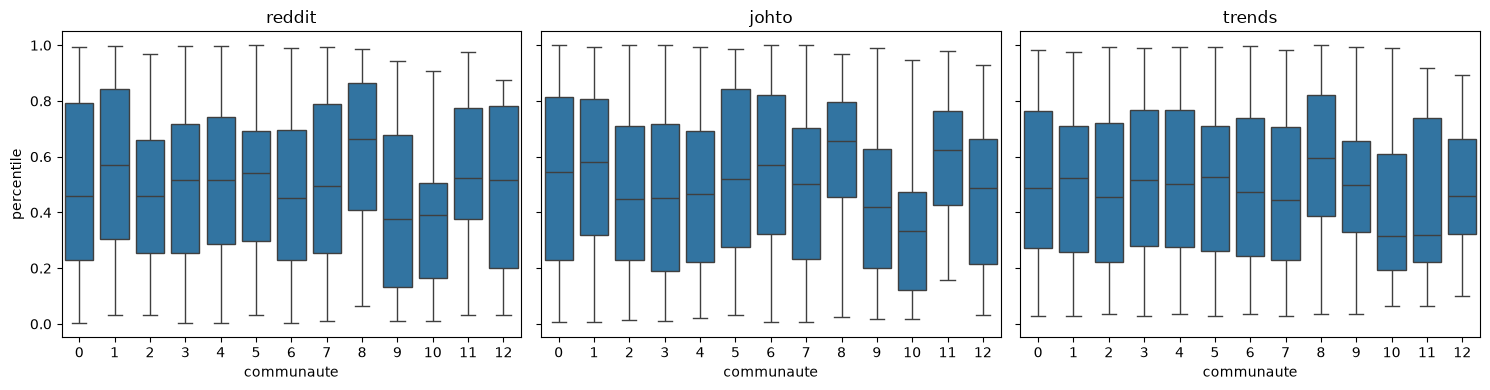

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, s in zip(axes, ["reddit", "johto", "trends"]):
    sns.boxplot(data=dp, x="communaute", y=s, ax=ax)
    ax.set_title(s); ax.set_ylabel("percentile")
plt.tight_layout(); plt.show()

## 4. Centralités et popularité

Pour chaque Pokémon, on calcule (comme au TP3) :
- le **degré** : nombre de voisins. Un Pokémon de fort degré ressemble à beaucoup d'autres (il est « banal ») ; un Pokémon de faible degré n'est le proche voisin de presque personne (il est « original ») ;
- la **similarité moyenne** à ses k voisins : plus elle est basse, plus le Pokémon est isolé dans l'espace des vecteurs ;
- l'**intermédiarité** (betweenness) : est-il sur beaucoup de plus courts chemins, comme un pont entre groupes ;
- la **proximité** (closeness) : est-il proche de tout le monde en moyenne ;
- le **coefficient de clustering** local : ses voisins sont-ils voisins entre eux.

Puis la corrélation de Spearman de chaque centralité avec chaque source de popularité.

In [16]:
cent = pd.DataFrame({
    "degre": dict(G.degree()),
    "similarite_voisins": {n: np.mean([G[n][v]["weight"] for v in G[n]]) for n in G},
    "intermediarite": nx.betweenness_centrality(G, seed=SEED),
    "proximite": nx.closeness_centrality(G),
    "clustering": nx.clustering(G),
})
# pour l'originalité « pure », la similarité aux k plus proches voisins (avant symétrisation)
cent["sim_k_voisins"] = pd.Series(1 - dist[:, 1:K + 1].mean(axis=1), index=noeuds)
cent.describe().round(3)

,degre,similarite_voisins,intermediarite,proximite,clustering,sim_k_voisins
count,1025.000,1025.000,1025.000,1025.000,1025.000,1025.000
mean,13.701,0.608,0.003,0.271,0.323,0.639
std,4.007,0.061,0.002,0.012,0.111,0.082
min,10.000,0.428,0.000,0.223,0.067,0.428
25%,11.000,0.568,0.001,0.264,0.244,0.580
50%,13.000,0.614,0.002,0.272,0.311,0.639
75%,15.000,0.652,0.003,0.279,0.385,0.695
max,31.000,0.755,0.013,0.310,0.764,0.859


La similarité moyenne d'un Pokémon à ses 10 plus proches voisins va de 0,43 (très à part) à 0,86 (il a des quasi-jumeaux).

In [17]:
lignes = []
for c in cent.columns:
    for s in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
        v = cent[[c]].join(dp[s]).dropna()
        rho, p = spearmanr(v[c], v[s])
        lignes.append({"centralite": c, "source": s, "rho": rho, "p": p})
res_c = pd.DataFrame(lignes)
tab = res_c.assign(txt=res_c.rho.round(2).astype(str) + np.where(res_c.p < 0.05, " *", "")).pivot(index="centralite", columns="source", values="txt")
tab[["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]]

source,reddit,johto,trends,resid_reddit,resid_johto,resid_trends
centralite,,,,,,
clustering,0.01,-0.03,-0.05,-0.02,0.02,-0.04
degre,0.02,0.05,0.11 *,-0.01,0.01,0.04
intermediarite,-0.05,0.01,0.07 *,-0.01,-0.02,0.03
proximite,-0.07,0.01,0.08 *,-0.01,-0.02,0.06
sim_k_voisins,0.03,0.02,0.08 *,-0.02,0.01,0.02
similarite_voisins,0.03,0.02,0.06,-0.01,0.02,0.01


Les centralités ne sont **presque pas liées à la popularité** : tous les rho sont entre -0,07 et 0,11. Les seuls significatifs sont faibles et uniquement sur Google Trends (degré 0,11, proximité et originalité 0,08, intermédiarité 0,07). Sur les résidus, il ne reste rien. Être un Pokémon « original » ou « banal » dans ce réseau ne rend ni plus ni moins populaire.

In [18]:
# les plus « originaux » (similarité la plus basse à leurs k voisins) et les plus « banals »
o = cent.join(table[["nom_fr"]]).join(dp[["reddit", "johto", "trends"]]).sort_values("sim_k_voisins")
print("Les plus originaux :"); display(o.head(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))
print("Les plus banals :"); display(o.tail(10)[["nom_fr", "sim_k_voisins", "degre", "reddit", "johto", "trends"]].round(2))

Les plus originaux :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
618,Limonde,0.43,10,0.54,0.27,0.58
337,Séléroc,0.45,10,0.23,0.36,0.41
101,Électrode,0.45,10,0.35,0.20,0.98
987,Flotte-Mèche,0.45,10,NaN,0.77,0.42
45,Rafflesia,0.45,10,0.76,0.67,0.53
617,Limaspeed,0.45,10,0.39,0.18,0.10
446,Goinfrex,0.46,10,0.71,0.62,0.65
863,Berserkatt,0.46,10,NaN,0.50,0.16
752,Tarenbulle,0.46,10,0.52,0.69,0.14
790,Cosmovum,0.46,10,0.01,0.07,0.39


Les plus banals :


,nom_fr,sim_k_voisins,degre,reddit,johto,trends
650,Marisson,0.83,20,0.56,0.53,0.60
511,Feuillajou,0.83,24,0.17,0.27,0.38
631,Aflamanoir,0.83,21,0.17,0.13,0.04
126,Magmar,0.84,19,0.67,0.30,0.77
252,Arcko,0.84,28,0.88,0.76,0.68
467,Maganon,0.85,29,0.52,0.36,0.41
810,Ouistempo,0.85,23,NaN,0.73,0.63
734,Manglouton,0.85,26,0.00,0.02,0.17
506,Ponchiot,0.85,25,0.09,0.66,0.26
504,Ratentif,0.86,27,0.01,0.05,0.33


Les plus originaux sont des Pokémon au design atypique (Limonde, Séléroc, Électrode, Flotte-Mèche, Rafflesia, Cosmovum…), et leur popularité est très variable (Cosmovum est tout en bas, Rafflesia plutôt aimé). Électrode a 0,98 sur Google Trends, mais c'est un des noms ambigus du notebook 02 (*electrode* est un mot courant), donc ce chiffre ne dit rien du Pokémon. Les plus banals sont surtout des stades 1 « petit mammifère » ou Feu (Ratentif, Ponchiot, Manglouton, Ouistempo, Arcko, Magmar) : là aussi on trouve des Pokémon très aimés (Arcko) et très peu aimés (Ratentif, Manglouton).

In [19]:
# l'originalité est-elle liée aux effets attendus ? (les légendaires sont peut-être juste plus « à part »)
o2 = cent[["sim_k_voisins", "degre"]].join(table[["legendaire", "fabuleux", "stade_categorie", "generation"]])
display(o2.groupby("stade_categorie")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("legendaire")[["sim_k_voisins", "degre"]].mean().round(3))
display(o2.groupby("generation")[["sim_k_voisins", "degre"]].mean().round(3))

,sim_k_voisins,degre
stade_categorie,,
sans évolution,0.621,13.886
stade 1,0.660,14.438
stade 2,0.628,12.766
stade 3,0.643,14.132


,sim_k_voisins,degre
legendaire,,
False,0.638,13.534
True,0.651,15.958


,sim_k_voisins,degre
generation,,
1,0.656,13.821
2,0.647,13.750
3,0.633,13.185
4,0.647,14.280
5,0.637,13.455
6,0.640,13.556
7,0.616,13.818
8,0.632,14.031
9,0.636,13.633


L'originalité ne dépend presque pas du stade, de la génération ou du statut de légendaire : les moyennes sont toutes très proches (0,62 à 0,66). Les légendaires ont même un peu plus de voisins (16,0 contre 13,5).

## 5. Les Pokémon populaires sont-ils voisins de Pokémon populaires ?

C'est l'**assortativité** : si on prend chaque arête, est-ce que les deux bouts ont une popularité proche ? On calcule le coefficient d'assortativité numérique de networkx pour chaque source (sur les Pokémon qui ont une valeur). Pour savoir si la valeur obtenue est grande, on la compare à ce qu'on obtient en **mélangeant la popularité au hasard** entre les Pokémon (test de permutation, 200 tirages).

In [20]:
def assortativite(G, valeurs):
    H = G.subgraph(valeurs.dropna().index).copy()
    nx.set_node_attributes(H, valeurs.dropna().to_dict(), "x")
    return nx.numeric_assortativity_coefficient(H, "x")

rng = np.random.default_rng(SEED)
lignes = []
for s in ["reddit", "johto", "trends", "resid_reddit", "resid_johto", "resid_trends"]:
    v = dp[s].dropna()
    r_obs = assortativite(G, v)
    r_perm = [assortativite(G, pd.Series(rng.permutation(v.values), index=v.index)) for _ in range(200)]
    lignes.append({"source": s, "assortativite": r_obs, "perm_moyenne": np.mean(r_perm), "perm_max": np.max(r_perm),
                   "p_permutation": (np.sum(np.array(r_perm) >= r_obs) + 1) / 201})
pd.DataFrame(lignes).set_index("source").round(3)

,assortativite,perm_moyenne,perm_max,p_permutation
source,,,,
reddit,0.141,-0.000,0.050,0.005
johto,0.187,-0.001,0.027,0.005
trends,0.092,-0.001,0.037,0.005
resid_reddit,0.039,-0.001,0.045,0.010
resid_johto,0.065,-0.001,0.038,0.005
resid_trends,0.020,-0.001,0.032,0.030


En revanche, les Pokémon populaires **sont plutôt voisins de Pokémon populaires** : l'assortativité vaut 0,14 (Reddit), 0,19 (Johto Times) et 0,09 (Google). C'est faible, mais bien au-dessus de ce que donne un mélange au hasard (jamais plus de 0,05 en 200 tirages, p = 0,005).

Sur les résidus, l'assortativité tombe à 0,02-0,07 : elle reste significative (p ≤ 0,03) mais devient très faible. Donc la ressemblance entre voisins populaires vient surtout des effets attendus (même type, même stade…), et seulement un peu d'autre chose.

reddit  rho = 0.335  p = 1.3e-22  (n = 809)
johto   rho = 0.431  p = 9.9e-48  (n = 1025)
trends  rho = 0.262  p = 1.5e-17  (n = 1025)


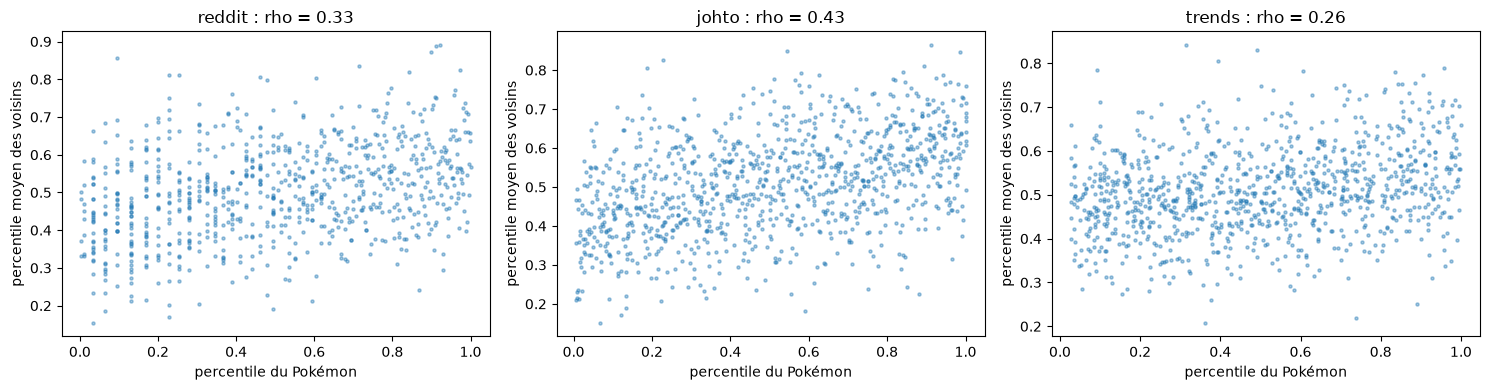

In [21]:
# version plus parlante : la popularité d'un Pokémon contre la popularité moyenne de ses voisins
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s in zip(axes, ["reddit", "johto", "trends"]):
    v = dp[s]
    moy_v = pd.Series({n: v.reindex(list(G[n])).mean() for n in G})
    w = pd.DataFrame({"soi": v, "voisins": moy_v}).dropna()
    ax.scatter(w.soi, w.voisins, s=5, alpha=.4)
    rho, p = spearmanr(w.soi, w.voisins)
    ax.set_title(f"{s} : rho = {rho:.2f}")
    print(f"{s:7s} rho = {rho:.3f}  p = {p:.2g}  (n = {len(w)})")
    ax.set_xlabel("percentile du Pokémon"); ax.set_ylabel("percentile moyen des voisins")
plt.tight_layout(); plt.show()

Avec la popularité moyenne des voisins, on voit la même chose : rho = 0,34 (Reddit), 0,43 (Johto Times) et 0,26 (Google), tous très significatifs. Le nuage reste très dispersé : avoir des voisins populaires ne garantit rien.

## 6. node2vec et t-SNE

node2vec (TP4) : on fait des **marches aléatoires** dans le graphe, on les traite comme des « phrases » dont les « mots » sont les Pokémon, et **Word2Vec** apprend un vecteur par Pokémon de façon que ceux qui apparaissent dans les mêmes marches aient des vecteurs proches. On a fait les marches à la main (même fonction qu'au TP4).

Pour les réglages, on reste proche de ce qu'on a fait au TP4 :
- **p = q = 1** : des marches aléatoires classiques, sans favoriser ni le retour en arrière ni l'exploration au loin. On n'a pas de raison de préférer l'un ou l'autre ici ;
- **10 marches de 40 pas** par Pokémon : avec un degré moyen autour de 14, une marche de 40 pas a le temps de sortir du voisinage direct, et 10 marches suffisent pour que chaque Pokémon apparaisse souvent ;
- **vecteurs de dimension 16** : on n'a que 1 025 Pokémon, et on veut juste une carte en 2D derrière, donc pas besoin de grands vecteurs ;
- **fenêtre de 5** : Word2Vec considère que deux Pokémon à moins de 5 pas dans une marche sont « dans le même contexte ».

Ensuite, **t-SNE** projette ces vecteurs en 2D pour faire une carte. On garde la **perplexité par défaut (30)** : elle correspond à peu près au nombre de voisins qu'on regarde, et 30 c'est raisonnable pour 1 025 points (ni trop local, ni trop global). On mesure avec la **trustworthiness** si les voisins sur la carte sont bien des voisins dans l'espace d'origine (1 = parfait).

In [22]:
from gensim.models import Word2Vec

def marches_node2vec(G, n_marches=10, longueur=40, p=1.0, q=1.0, seed=0):
    rng = random.Random(seed)
    voisins_de = {u: list(G[u]) for u in G}
    noeuds_, marches = list(G), []
    for _ in range(n_marches):
        rng.shuffle(noeuds_)
        for depart in noeuds_:
            marche = [depart]
            while len(marche) < longueur:
                ns = voisins_de[marche[-1]]
                if len(marche) == 1:
                    marche.append(rng.choice(ns)); continue
                prec = marche[-2]
                poids = [1 / p if x == prec else 1 if G.has_edge(x, prec) else 1 / q for x in ns]
                marche.append(rng.choices(ns, weights=poids)[0])
            marches.append(marche)
    return marches

N2V_DIM, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q = 16, 10, 40, 1.0, 1.0
marches = marches_node2vec(G, N2V_MARCHES, N2V_LONGUEUR, N2V_P, N2V_Q, SEED)
phrases = [[str(n) for n in m] for m in marches]
w2v = Word2Vec(phrases, vector_size=N2V_DIM, window=5, min_count=0, sg=1, workers=1, seed=SEED, epochs=5)
N2V = np.array([w2v.wv[str(n)] for n in noeuds])
print(len(marches), "marches | vecteurs :", N2V.shape)

10250 marches | vecteurs : (1025, 16)


10 marches de 40 pas par Pokémon, soit 10 250 marches, et un vecteur de 16 dimensions par Pokémon.

In [23]:
# les voisins dans l'espace node2vec ressemblent-ils à ceux du graphe ?
from sklearn.metrics.pairwise import cosine_similarity
S = cosine_similarity(N2V)
pos = {n: i for i, n in enumerate(noeuds)}
for d in [6, 25, 94, 133, 448]:
    o = np.argsort(-S[pos[d]])[1:7]
    print(f"{table.loc[d, 'nom_fr']:12s} →", ", ".join(table.loc[noeuds[o], "nom_fr"]))

Dracaufeu    → Aflamanoir, Magmar, Maganon, Camérupt, Braségali, Flamoutan
Pikachu      → Voltoutou, Posipi, Galvaran, Pichu, Élekid, Pâtachiot
Ectoplasma   → Salarsen, Mewtwo, Wimessir, Groret, Nidoking, Avaltout
Évoli        → Ponchiot, Keunotor, Fouinette, Manglouton, Argouste, Ratentif
Lucario      → Pingoléon, Lézargus, Laggron, Brouhabam, Têtes-de-Fer, Pondralugon


Les voisins node2vec ressemblent à ceux du graphe, mais en un peu plus « large » : node2vec regarde aussi les voisins des voisins. Dracaufeu reste avec des Pokémon Feu (Aflamanoir, Magmar, Maganon, Camérupt…), Pikachu avec des Électrik (Voltoutou, Posipi, Pichu, Élekid…), et Lucario se retrouve avec d'autres combattants dressés (Pingoléon, Lézargus, Laggron…).

In [24]:
TSNE_PERPLEXITE = 30
tsne_n2v = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca").fit_transform(N2V)
tsne_x = TSNE(n_components=2, perplexity=TSNE_PERPLEXITE, random_state=SEED, init="pca", metric="cosine").fit_transform(X.values)
pd.DataFrame({
    "trustworthiness (10 voisins)": [trustworthiness(N2V, tsne_n2v, n_neighbors=10), trustworthiness(X.values, tsne_x, n_neighbors=10, metric="cosine")],
}, index=["node2vec → t-SNE (vs node2vec)", "vecteurs → t-SNE direct (vs vecteurs)"]).round(3)

,trustworthiness (10 voisins)
node2vec → t-SNE (vs node2vec),0.992
vecteurs → t-SNE direct (vs vecteurs),0.968


Les deux cartes t-SNE préservent très bien les voisinages : trustworthiness de 0,99 pour node2vec → t-SNE et 0,97 pour le t-SNE direct sur les vecteurs. La perplexité de 30 convient donc, on n'a pas besoin d'en tester d'autres.

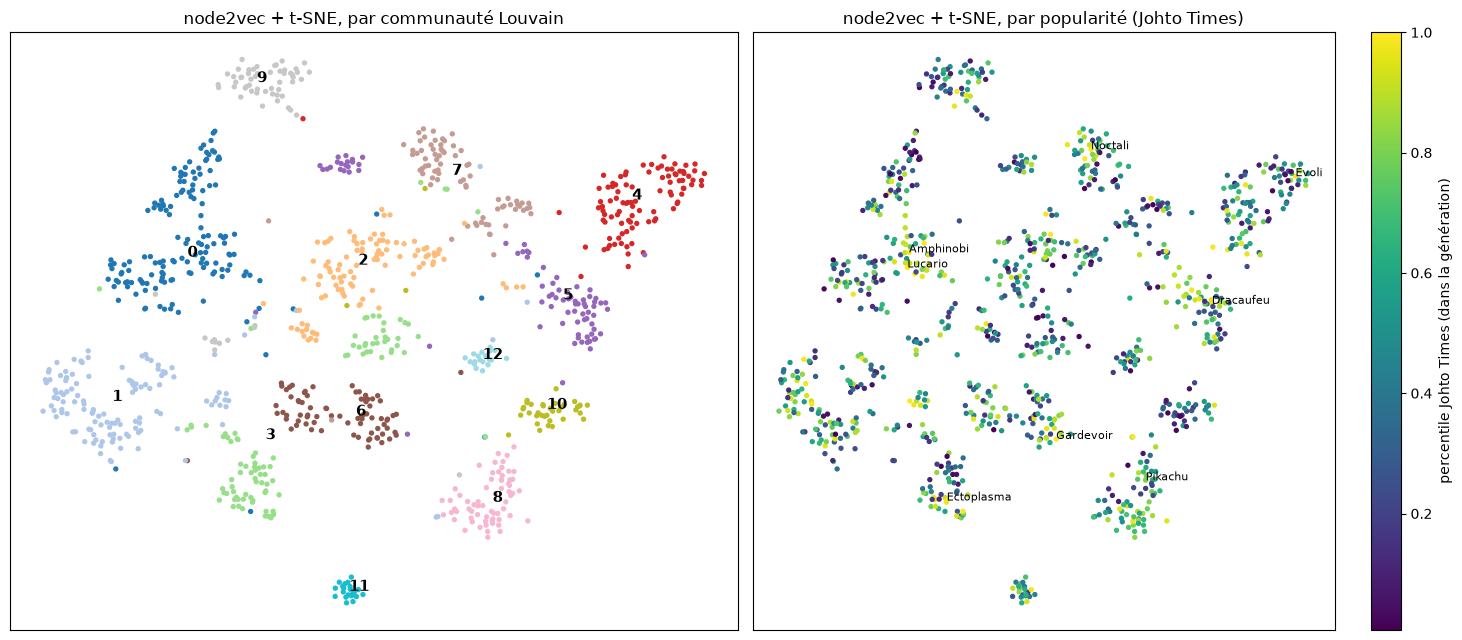

In [25]:
carte = pd.DataFrame(tsne_n2v, index=noeuds, columns=["x", "y"]).join(comm).join(dp[["johto", "reddit", "trends"]]).join(table[["nom_fr"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(carte.x, carte.y, c=carte.communaute, cmap="tab20", s=8)
for c, g in carte.groupby("communaute"):
    axes[0].text(g.x.median(), g.y.median(), str(c), fontsize=11, weight="bold")
axes[0].set_title("node2vec + t-SNE, par communauté Louvain")
sc = axes[1].scatter(carte.x, carte.y, c=carte.johto, cmap="viridis", s=8)
plt.colorbar(sc, ax=axes[1], label="percentile Johto Times (dans la génération)")
for n in [6, 25, 94, 133, 448, 197, 282, 658]:
    axes[1].annotate(table.loc[n, "nom_fr"], (carte.loc[n, "x"], carte.loc[n, "y"]), fontsize=8)
axes[1].set_title("node2vec + t-SNE, par popularité (Johto Times)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Sur la carte, les communautés Louvain forment des îlots bien séparés. Dans chaque îlot, la popularité est mélangée (des points clairs et foncés côte à côte), avec par endroits de petits groupes de Pokémon très aimés proches les uns des autres. Ça colle avec l'assortativité faible mais réelle qu'on a mesurée.

## 7. Export

In [26]:
noeuds_df = table[["nom_fr", "nom_en", "generation", "type1", "type2"]].join(comm).join(cent).join(
    pd.DataFrame(tsne_n2v, index=noeuds, columns=["tsne_x", "tsne_y"]))
noeuds_df.index.name = "dex"
aretes = pd.DataFrame([(u, v, w) for u, v, w in G.edges(data="weight")], columns=["source", "cible", "similarite"])
noeuds_df.to_csv(OUT / "reseau_noeuds.csv")
aretes.to_csv(OUT / "reseau_aretes.csv", index=False)
print(noeuds_df.shape, aretes.shape)

(1025, 14) (7022, 3)


Exports : 1 025 nœuds (communauté, centralités, coordonnées t-SNE) et 7 022 arêtes (avec la similarité), pour le graphe interactif dans Dash.